### importation des bibliotheque 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

###  charger le dataset 

In [3]:
df = pd.read_csv("Titanic-Dataset.csv")


In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 891
Nombre de colonnes : 12


In [6]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [7]:
df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### Partie 1.5 – Division des données (Train/Test Split)

In [8]:
X = df.drop(columns=['Survived'])
y = df['Survived']

#### Division des données

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Vérification

In [10]:
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (712, 11)
X_test : (179, 11)
y_train : (712,)
y_test : (179,)


### Partie 2 – Nettoyage des Données

### Gestion des valeurs manquantes

In [11]:
missing_percentage = X_train.isnull().mean() * 100

print(missing_percentage.sort_values(ascending=False))

Cabin          77.528090
Age            19.241573
Embarked        0.280899
Name            0.000000
Pclass          0.000000
PassengerId     0.000000
Sex             0.000000
Parch           0.000000
SibSp           0.000000
Fare            0.000000
Ticket          0.000000
dtype: float64


### A. Suppression de Cabin

In [12]:
if X_train['Cabin'].isnull().mean() > 0.40:
    X_train = X_train.drop(columns=['Cabin'])
    X_test = X_test.drop(columns=['Cabin'])

### B. Remplacement de Age par la Médiane

In [13]:
age_imputer = SimpleImputer(strategy='median')

X_train[['Age']] = age_imputer.fit_transform(X_train[['Age']])

X_test[['Age']] = age_imputer.transform(X_test[['Age']])

In [33]:
print(X_train)

     Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  Embarked_S
692       3  28.5      0      0  56.4958         1           0           1
481       2  28.5      0      0   0.0000         1           0           1
527       1  28.5      0      0  14.4542         1           0           1
855       3  18.0      0      1   9.3500         0           0           1
801       2  31.0      1      1  26.2500         0           0           1
..      ...   ...    ...    ...      ...       ...         ...         ...
359       3  28.5      0      0   7.8792         0           1           0
258       1  35.0      0      0  14.4542         0           0           0
736       3  48.0      1      3  34.3750         0           0           1
462       1  47.0      0      0  38.5000         1           0           1
507       1  28.5      0      0  26.5500         1           0           1

[712 rows x 8 columns]


### C. Remplacement de Embarked par le Mode

In [14]:
embarked_imputer = SimpleImputer(strategy='most_frequent')

X_train[['Embarked']] = embarked_imputer.fit_transform(
    X_train[['Embarked']]
)

X_test[['Embarked']] = embarked_imputer.transform(
    X_test[['Embarked']]
)

#### Vérification après nettoyage

In [16]:
print("Train missing values:")
print(X_train.isnull().sum())
print("Test missing values:")
print(X_test.isnull().sum())

Train missing values:
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64
Test missing values:
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


### Gestion des valeurs aberrantes (Outliers)

#####  A. Visualisation avec Boxplot

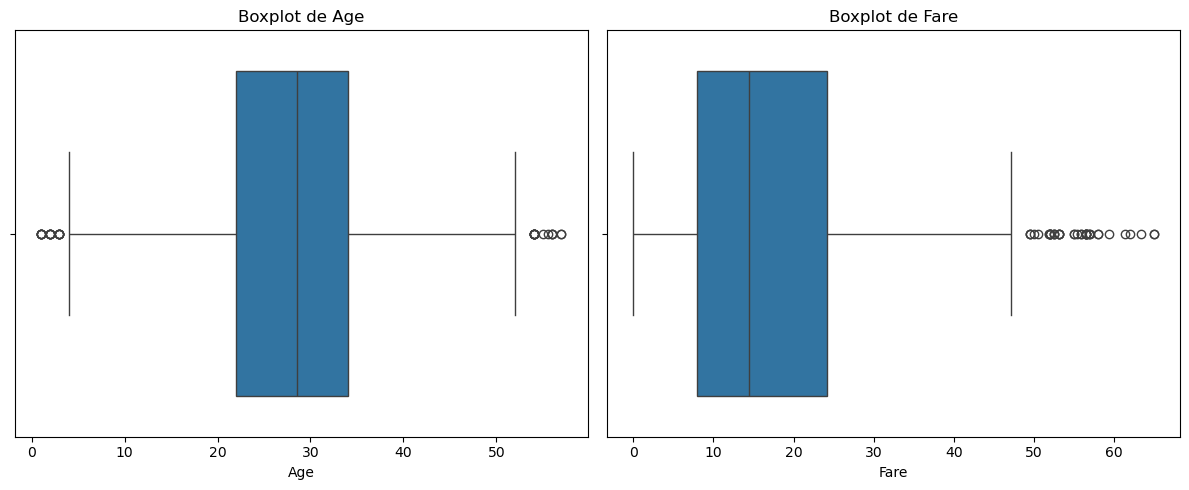

In [34]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=X_train['Age'])
plt.title('Boxplot de Age')

plt.subplot(1, 2, 2)
sns.boxplot(x=X_train['Fare'])
plt.title('Boxplot de Fare')

plt.tight_layout()
plt.show()

#### B. Détection avec la méthode IQR

In [19]:
outlier_limits = {}
for col in ['Age', 'Fare']:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    median = X_train[col].median()
    outlier_limits[col] = (lower, upper, median)
    print(col)
    print("Lower:", lower)
    print("Upper:", upper)

Age
Lower: 1.0
Upper: 57.0
Fare
Lower: -26.7605
Upper: 65.6563


### C. Remplacement des Outliers par la Médiane

In [20]:
for col in ['Age', 'Fare']:
    lower, upper, median = outlier_limits[col]
    X_train[col] = np.where(
        (X_train[col] < lower) | (X_train[col] > upper),
        median,
        X_train[col]
    )
    X_test[col] = np.where(
        (X_test[col] < lower) | (X_test[col] > upper),
        median,
        X_test[col]
    )

#### Partie 3 – Transformation des Données

##### Préparation des variables

In [21]:
columns_to_drop = ['PassengerId', 'Name', 'Ticket']
X_train = X_train.drop(columns=columns_to_drop, errors='ignore')
X_test = X_test.drop(columns=columns_to_drop, errors='ignore')

### Encodage des variables catégorielles

In [22]:
X_train = pd.get_dummies(
    X_train,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)
X_test = pd.get_dummies(
    X_test,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

In [23]:
X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

### Normalisation (Min-Max Scaling)

In [24]:
from sklearn.preprocessing import MinMaxScaler
columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()
minmax_scaler = MinMaxScaler()

X_train_norm = X_train.copy()
X_test_norm = X_test.copy()
X_train_norm[columns] = minmax_scaler.fit_transform(
    X_train[columns]
)
X_test_norm[columns] = minmax_scaler.transform(
    X_test[columns]
)

### Standardisation (Z-score)

In [25]:
from sklearn.preprocessing import StandardScaler
standard_scaler = StandardScaler()
X_train_std = X_train.copy()
X_test_std = X_test.copy()
X_train_std[columns] = standard_scaler.fit_transform(
    X_train[columns]
)
X_test_std[columns] = standard_scaler.transform(
    X_test[columns]
)

### Comparaison des distributions

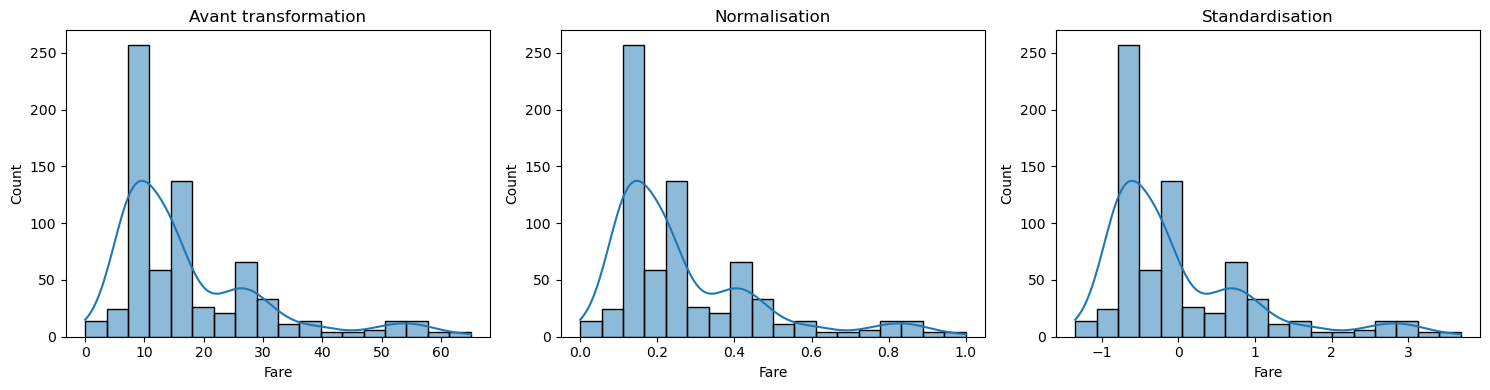

In [26]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
sns.histplot(X_train['Fare'], kde=True)
plt.title('Avant transformation')
plt.subplot(1, 3, 2)
sns.histplot(X_train_norm['Fare'], kde=True)
plt.title('Normalisation')
plt.subplot(1, 3, 3)
sns.histplot(X_train_std['Fare'], kde=True)
plt.title('Standardisation')
plt.tight_layout()
plt.show()

#### Partie 4 – Gestion des Données Déséquilibrées

### Identification du déséquilibre

In [27]:
print("Distribution des classes :")
print(y_train.value_counts())
print("\nPourcentage des classes :")
print(y_train.value_counts(normalize=True) * 100)

Distribution des classes :
Survived
0    439
1    273
Name: count, dtype: int64

Pourcentage des classes :
Survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64


### Undersampling

In [29]:
from imblearn.under_sampling import RandomUnderSampler
undersampler = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = undersampler.fit_resample(
    X_train_std,
    y_train
)

### verification 

In [30]:
print("Avant Undersampling:")
print(y_train.value_counts())
print("\nAprès Undersampling:")
print(y_train_under.value_counts())

Avant Undersampling:
Survived
0    439
1    273
Name: count, dtype: int64

Après Undersampling:
Survived
0    273
1    273
Name: count, dtype: int64


### Oversampling avec SMOTE

In [31]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_std,
    y_train
)

#### verification 

In [32]:
print("Avant SMOTE:")
print(y_train.value_counts())
print("\nAprès SMOTE:")
print(y_train_smote.value_counts())

Avant SMOTE:
Survived
0    439
1    273
Name: count, dtype: int64

Après SMOTE:
Survived
1    439
0    439
Name: count, dtype: int64
